# Experiment 186 · Health transfer and consistency

**Complete** · Health transfer and objective comparisons saved · ETA 0h 00m 00s

## Stage A · Does an earlier health change predict a later gain?

A health change runs from checkpoint 0 to checkpoint 1. Its target is the change in downstream balanced accuracy from checkpoint 1 to checkpoint 2. Lower MSE counts as better health. Models fit seeds 2029–2032 and hold out 2033–2034. The factorial test additionally fits 16k→24k health changes and tests 40k→48k changes, both forecasting a 24k-arrival task change. The broad-only test scores four 12k→12k windows at every seed. The two masks and different policies per seed share training data. Correlations and errors are descriptive, with per-seed checks in the JSON.

### Factorial trajectories

32 fit observations and 16 held-out observations.

| Task | Predictor | Held-out ρ | MAE (pp) | Seed 2033 ρ | Seed 2034 ρ |
| --- | --- | --- | --- | --- | --- |
 | scene | Training mean | — | 1.27 | — | — | 
 | scene | Retrieval only | -0.010 | 1.30 | -0.180 | +0.263 | 
 | scene | All health metrics | -0.399 | 1.75 | -0.707 | +0.156 | 
 | lighting | Training mean | — | 0.69 | — | — | 
 | lighting | Retrieval only | -0.385 | 0.88 | -0.370 | -0.339 | 
 | lighting | All health metrics | +0.133 | 0.88 | +0.575 | -0.365 | 

### Broad replay checkpoints

16 fit observations and 8 held-out observations.

| Task | Predictor | Held-out ρ | MAE (pp) | Seed 2033 ρ | Seed 2034 ρ |
| --- | --- | --- | --- | --- | --- |
 | scene | Training mean | — | 1.66 | — | — | 
 | scene | Retrieval only | -0.228 | 1.75 | -0.400 | -0.200 | 
 | scene | All health metrics | +0.167 | 1.90 | +0.000 | +0.400 | 
 | weather | Training mean | — | 1.97 | — | — | 
 | weather | Retrieval only | +0.635 | 1.96 | +0.200 | +1.000 | 
 | weather | All health metrics | +0.048 | 2.42 | +0.000 | -0.200 | 
 | lighting | Training mean | — | 0.17 | — | — | 
 | lighting | Retrieval only | +0.329 | 0.27 | — | +0.316 | 
 | lighting | All health metrics | +0.764 | 0.43 | — | +0.949 | 

### Final retrieval and downstream agreement across mixture policies

| Task | 2029 | 2030 | 2031 | 2032 | 2033 | 2034 |
| --- | --- | --- | --- | --- | --- | --- |
 | scene | +0.154 | +0.200 | +0.000 | +0.564 | -0.200 | -0.100 | 
 | weather | +0.800 | -0.359 | +0.600 | +0.000 | +0.700 | -0.200 | 

This final-time comparison is contemporaneous. The held-out timing tests above are the primary evidence for prediction. The pilot is triggered when neither held-out design has two tasks with a predictive correlation of at least 0.30, lower MAE than the training mean, and a positive correlation on both test seeds.

## Stage B · Two-view consistency pilot

The two replay mixtures use a 25% replacement budget and the same singleton MAE updates. Every eighth arrival, both arms encode two mild views of the training image and three causal past images from distinct clips. The auxiliary loss aligns matching views using symmetric cross-view contrastive classification. The nonmatching clips provide negatives to resist collapse. The control runs the same graph with zero weight, and the treatment uses λ = 0.05. Temperature is 0.2. Model, optimizer, images, masks, and extra view compute are paired.

The pilot branches both replay mixtures from a shared broad-random checkpoint after 32,000 online arrivals. It follows three seeds and two paired masks for another 8,192 arrivals, with the same external probe fit/test panels. Pilot deltas are descriptive.

| Seed | Mask | Broad | Consistency | Arrivals | Replay updates | Train time |
| --- | --- | --- | --- | --- | --- | --- |
 | 2029 | 1 | 25% | Off | 8,192 | 2048 | 0h 01m 19s | 
 | 2029 | 1 | 25% | On | 8,192 | 2048 | 0h 01m 12s | 
 | 2029 | 1 | 100% | Off | 8,192 | 2048 | 0h 01m 13s | 
 | 2029 | 1 | 100% | On | 8,192 | 2048 | 0h 01m 12s | 
 | 2029 | 2 | 25% | Off | 8,192 | 2048 | 0h 01m 13s | 
 | 2029 | 2 | 25% | On | 8,192 | 2048 | 0h 01m 12s | 
 | 2029 | 2 | 100% | Off | 8,192 | 2048 | 0h 01m 12s | 
 | 2029 | 2 | 100% | On | 8,192 | 2048 | 0h 01m 12s | 
 | 2031 | 1 | 25% | Off | 8,192 | 2048 | 0h 01m 12s | 
 | 2031 | 1 | 25% | On | 8,192 | 2048 | 0h 01m 13s | 
 | 2031 | 1 | 100% | Off | 8,192 | 2048 | 0h 01m 14s | 
 | 2031 | 1 | 100% | On | 8,192 | 2048 | 0h 01m 12s | 
 | 2031 | 2 | 25% | Off | 8,192 | 2048 | 0h 01m 12s | 
 | 2031 | 2 | 25% | On | 8,192 | 2048 | 0h 01m 11s | 
 | 2031 | 2 | 100% | Off | 8,192 | 2048 | 0h 01m 13s | 
 | 2031 | 2 | 100% | On | 8,192 | 2048 | 0h 01m 13s | 
 | 2034 | 1 | 25% | Off | 8,192 | 2048 | 0h 01m 12s | 
 | 2034 | 1 | 25% | On | 8,192 | 2048 | 0h 01m 12s | 
 | 2034 | 1 | 100% | Off | 8,192 | 2048 | 0h 01m 13s | 
 | 2034 | 1 | 100% | On | 8,192 | 2048 | 0h 01m 12s | 
 | 2034 | 2 | 25% | Off | 8,192 | 2048 | 0h 01m 12s | 
 | 2034 | 2 | 25% | On | 8,192 | 2048 | 0h 01m 12s | 
 | 2034 | 2 | 100% | Off | 8,192 | 2048 | 0h 01m 13s | 
 | 2034 | 2 | 100% | On | 8,192 | 2048 | 0h 01m 13s | 

Positive means the auxiliary arm improved the metric. Downstream gains and retrieval are shown in percentage points.

| Arrivals | Broad | Pairs | unseen | historical | retrieval | scene | weather | lighting | rankme |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | 2048 | 25% | 6 | -0.000 | +0.001 | +0.521 | -0.401 | -0.309 | +0.000 | +0.149 | 
 | 2048 | 100% | 6 | +0.001 | +0.000 | +0.163 | +0.154 | -0.103 | -0.321 | +0.166 | 
 | 4096 | 25% | 6 | +0.001 | +0.000 | +0.374 | +0.340 | +0.103 | -0.154 | +0.215 | 
 | 4096 | 100% | 6 | +0.001 | -0.000 | +0.521 | +0.463 | -0.309 | -0.314 | +0.238 | 
 | 8192 | 25% | 6 | -0.001 | -0.003 | +0.244 | +0.648 | -0.772 | -0.314 | +0.451 | 
 | 8192 | 100% | 6 | +0.001 | +0.000 | -0.488 | +0.741 | -0.154 | -0.314 | +0.340 | 

In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-health-transfer')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


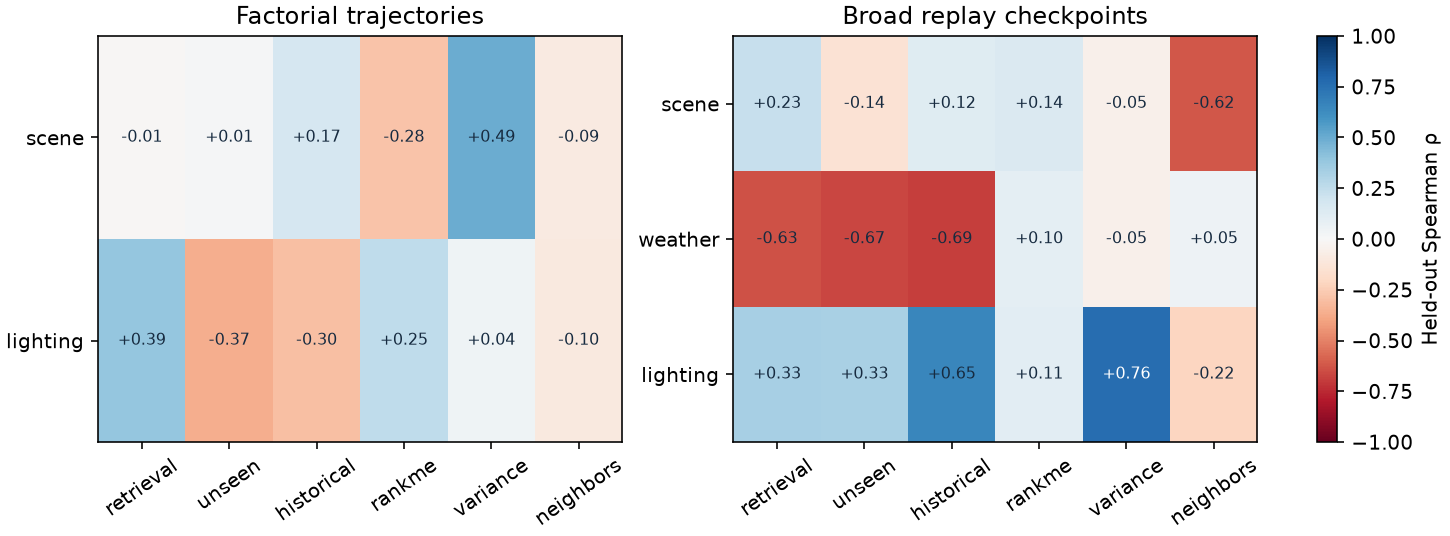